In [1]:
import sys
sys.path.append("..")
%load_ext autoreload
%autoreload 2

In [2]:
from src.data import load_prices

In [3]:
DB_PATH = "../../financial-data-pipeline/data/market.db"

In [4]:
load_prices(DB_PATH, "SPY").head()

,adj_close
date,
2014-01-02,147.831345
2014-01-03,147.807159
2014-01-06,147.378738
2014-01-07,148.283936
2014-01-08,148.316269


In [5]:
load_prices(DB_PATH, "QQQ").head()

,adj_close
date,
2014-01-02,78.874672
2014-01-03,78.305305
2014-01-06,78.016083
2014-01-07,78.739098
2014-01-08,78.910820


In [6]:
load_prices(DB_PATH, "FAKE")

ValueError: No price data found for ticker FAKE

In [7]:
from src.signals import ma_signal

In [8]:
spy = load_prices(DB_PATH, "SPY")

In [14]:
spy_signal = ma_signal(spy["adj_close"])

In [15]:
spy_signal.value_counts()

adj_close
1    2307
0     895
Name: count, dtype: int64

In [16]:
type(spy_signal)

pandas.Series

In [17]:
from src.engine import run_backtest

In [ ]:
run_backtest(spy["adj_close"], spy_signal.iloc[1:])

ValueError: prices and signal must have the same dates

In [19]:
bt = run_backtest(spy["adj_close"], spy_signal)

In [20]:
bt.loc["2014-04-08":"2014-04-11"]

,daily_return,position,strat_ret
date,,,
2014-04-08,0.004123,1.0,0.004123
2014-04-09,0.010751,1.0,0.010751
2014-04-10,-0.021006,1.0,-0.021006
2014-04-11,-0.009009,0.0,-0.000000


In [21]:
bt.head()

,daily_return,position,strat_ret
date,,,
2014-01-02,NaN,NaN,NaN
2014-01-03,-0.000164,0.0,-0.0
2014-01-06,-0.002899,0.0,-0.0
2014-01-07,0.006142,0.0,0.0
2014-01-08,0.000218,0.0,0.0


In [ ]:
bh_equity = (1 + bt["daily_return"].fillna(0)).cumprod()
strat_equity = (1 + bt["strat_ret"].fillna(0)).cumprod()  

In [28]:
print(bh_equity.iloc[-1], strat_equity.iloc[-1])

5.217770139679148 2.2493385991812542


In [30]:
strat_equity.head(10)

date
2014-01-02    1.0
2014-01-03    1.0
2014-01-06    1.0
2014-01-07    1.0
2014-01-08    1.0
2014-01-09    1.0
2014-01-10    1.0
2014-01-13    1.0
2014-01-14    1.0
2014-01-15    1.0
Name: strat_ret, dtype: float64

In [31]:
bt.head(10)

,daily_return,position,strat_ret
date,,,
2014-01-02,NaN,NaN,NaN
2014-01-03,-0.000164,0.0,-0.0
2014-01-06,-0.002899,0.0,-0.0
2014-01-07,0.006142,0.0,0.0
2014-01-08,0.000218,0.0,0.0
2014-01-09,0.000654,0.0,0.0
2014-01-10,0.002723,0.0,0.0
2014-01-13,-0.013305,0.0,-0.0
2014-01-14,0.010898,0.0,0.0


In [33]:
import matplotlib.pyplot as plt

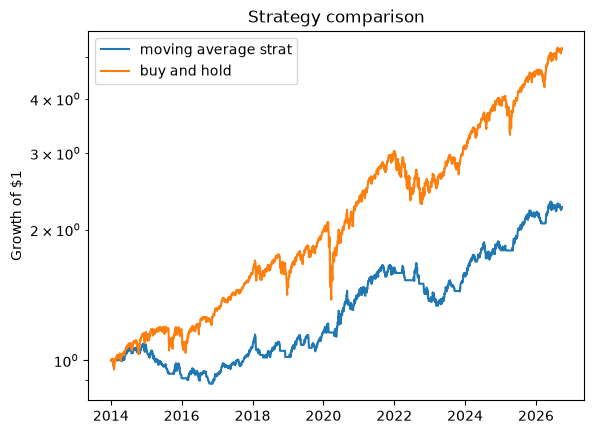

In [ ]:
plt.plot(bt.index, strat_equity, label = "moving average strat")
plt.plot(bt.index, bh_equity, label = "buy and hold")
plt.legend()
plt.title("SPY: MA50 rule vs buy-and-hold (before costs)")
plt.ylabel("Growth of $1")
plt.yscale("log")
plt.show()

In [37]:
bt = run_backtest(spy["adj_close"], spy_signal)

In [38]:
bt.head()

,daily_return,position,strat_ret,turnover,net_ret
date,,,,,
2014-01-02,NaN,0.0,NaN,0.0,NaN
2014-01-03,-0.000164,0.0,-0.0,0.0,-0.0
2014-01-06,-0.002899,0.0,-0.0,0.0,-0.0
2014-01-07,0.006142,0.0,0.0,0.0,0.0
2014-01-08,0.000218,0.0,0.0,0.0,0.0


In [39]:
bh_equity = (1 + bt["daily_return"].fillna(0)).cumprod()
strat_equity = (1 + bt["strat_ret"].fillna(0)).cumprod()  
print(bh_equity.iloc[-1], strat_equity.iloc[-1])

5.217770139679148 2.2493385991812542


In [41]:
bt_10 = run_backtest(spy["adj_close"], spy_signal, cost_bps=10)
bh_equity_10 = (1 + bt_10["daily_return"].fillna(0)).cumprod()
strat_equity_10 = (1 + bt_10["net_ret"].fillna(0)).cumprod()  
print(bh_equity_10.iloc[-1], strat_equity_10.iloc[-1])

5.217770139679148 1.7890097838625305


In [42]:
bt_30 = run_backtest(spy["adj_close"], spy_signal, cost_bps=30)
strat_equity_30 = (1 + bt_30["net_ret"].fillna(0)).cumprod()  
print(strat_equity_30.iloc[-1])

1.1309142386985358


In [43]:
bt_10["turnover"].sum()

np.float64(229.0)

In [48]:
from src.metrics import cagr
cagr(bt["daily_return"]), cagr(bt_10["net_ret"])

(np.float64(0.13889657768739672), np.float64(0.046856217269904965))

In [50]:
from src.metrics import ann_vol
ann_vol(bt["daily_return"]), ann_vol(bt_10["net_ret"])


(np.float64(0.17125907238370874), np.float64(0.10287454569728885))

In [51]:
from src.metrics import sharpe
sharpe(bt["daily_return"]), sharpe(bt_10["net_ret"])


(np.float64(0.8454596650234235), np.float64(0.4967675739842907))

In [55]:
from src.metrics import max_drawdown
max_drawdown(bt["daily_return"]), max_drawdown(bt_10["net_ret"])


(np.float64(-0.3371727855161352), np.float64(-0.2426665118918144))

In [56]:
from src.metrics import drawdown_series
drawdown_series(bt["daily_return"]).idxmin(), drawdown_series(bt_10["net_ret"]).idxmin()

(Timestamp('2020-03-23 00:00:00'), Timestamp('2016-11-11 00:00:00'))